##Import Python libraries

In [2]:

# Import the Pandas library
import pandas as pd

# Import NumPy
import numpy as np

# Import Matplotlib
import matplotlib.pyplot as plt

# Import Seaborn
import seaborn as sns

# Display all columns in the output
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")


All libraries imported successfully!


##Load the dataset

In [3]:

import pandas as pd
import zipfile
import io
import requests

# Official UCI dataset download URL
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download the dataset
response = requests.get(url)
response.raise_for_status()

# Open the downloaded ZIP file
with zipfile.ZipFile(io.BytesIO(response.content)) as outer_zip:

    # Open the student.zip file inside the downloaded archive
    with zipfile.ZipFile(io.BytesIO(outer_zip.read("student.zip"))) as inner_zip:

        # Load the Mathematics student dataset
        with inner_zip.open("student-mat.csv") as file:
            df = pd.read_csv(file, sep=";")

# Display first five records
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


##Understand your dataset

In [4]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (395, 33)
Total Rows: 395
Total Columns: 33


In [5]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [6]:
# Display statistical summary
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [7]:
# Count duplicate rows
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


## EDA

In [8]:

# Display first 10 final grades
print(df['G3'].head(10))

# Find average final grade
print("Average Final Grade:", df['G3'].mean())

# Find highest final grade
print("Highest Final Grade:", df['G3'].max())

# Find lowest final grade
print("Lowest Final Grade:", df['G3'].min())


0     6
1     6
2    10
3    15
4    10
5    15
6    11
7     6
8    19
9    15
Name: G3, dtype: int64
Average Final Grade: 10.415189873417722
Highest Final Grade: 20
Lowest Final Grade: 0


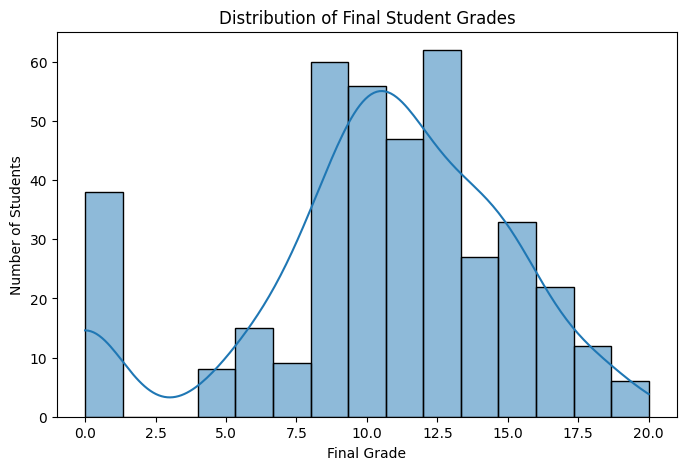

In [9]:

# Create a figure
plt.figure(figsize=(8, 5))

# Plot final grade distribution
sns.histplot(data=df, x='G3', bins=15, kde=True)

# Add graph title
plt.title("Distribution of Final Student Grades")

# Add axis labels
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

# Display graph
plt.show()


In [10]:

# Calculate average final grade for each study-time category
study_analysis = df.groupby('studytime')['G3'].mean()

# Display results
print(study_analysis)


studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


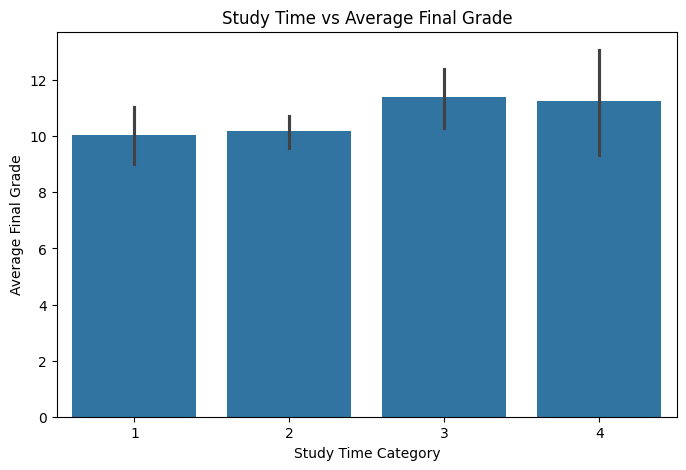

In [11]:

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='studytime', y='G3')

plt.title("Study Time vs Average Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")

plt.show()


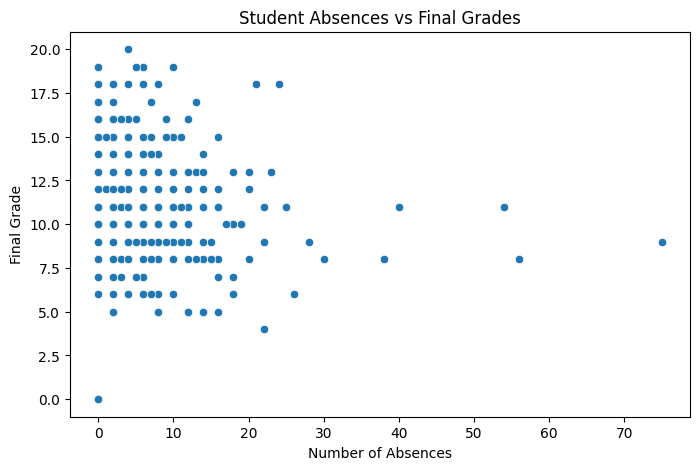

In [12]:

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='absences', y='G3')

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()


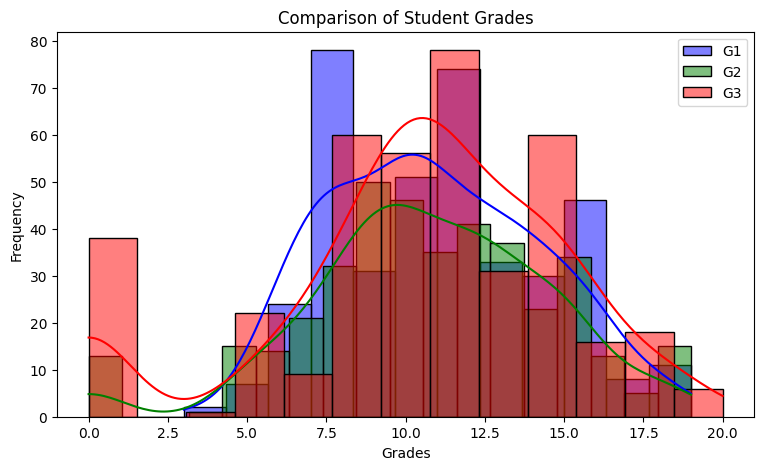

In [13]:

plt.figure(figsize=(9, 5))

sns.histplot(df['G1'], color='blue', label='G1', kde=True)
sns.histplot(df['G2'], color='green', label='G2', kde=True)
sns.histplot(df['G3'], color='red', label='G3', kde=True)

plt.title("Comparison of Student Grades")
plt.xlabel("Grades")
plt.ylabel("Frequency")

plt.legend()
plt.show()


In [14]:

# Calculate correlation between numerical columns
correlation = df.corr(numeric_only=True)

# Display correlation values
print(correlation)


                 age      Medu      Fedu  traveltime  studytime  failures  \
age         1.000000 -0.163658 -0.163438    0.070641  -0.004140  0.243665   
Medu       -0.163658  1.000000  0.623455   -0.171639   0.064944 -0.236680   
Fedu       -0.163438  0.623455  1.000000   -0.158194  -0.009175 -0.250408   
traveltime  0.070641 -0.171639 -0.158194    1.000000  -0.100909  0.092239   
studytime  -0.004140  0.064944 -0.009175   -0.100909   1.000000 -0.173563   
failures    0.243665 -0.236680 -0.250408    0.092239  -0.173563  1.000000   
famrel      0.053940 -0.003914 -0.001370   -0.016808   0.039731 -0.044337   
freetime    0.016434  0.030891 -0.012846   -0.017025  -0.143198  0.091987   
goout       0.126964  0.064094  0.043105    0.028540  -0.063904  0.124561   
Dalc        0.131125  0.019834  0.002386    0.138325  -0.196019  0.136047   
Walc        0.117276 -0.047123 -0.012631    0.134116  -0.253785  0.141962   
health     -0.062187 -0.046878  0.014742    0.007501  -0.075616  0.065827   

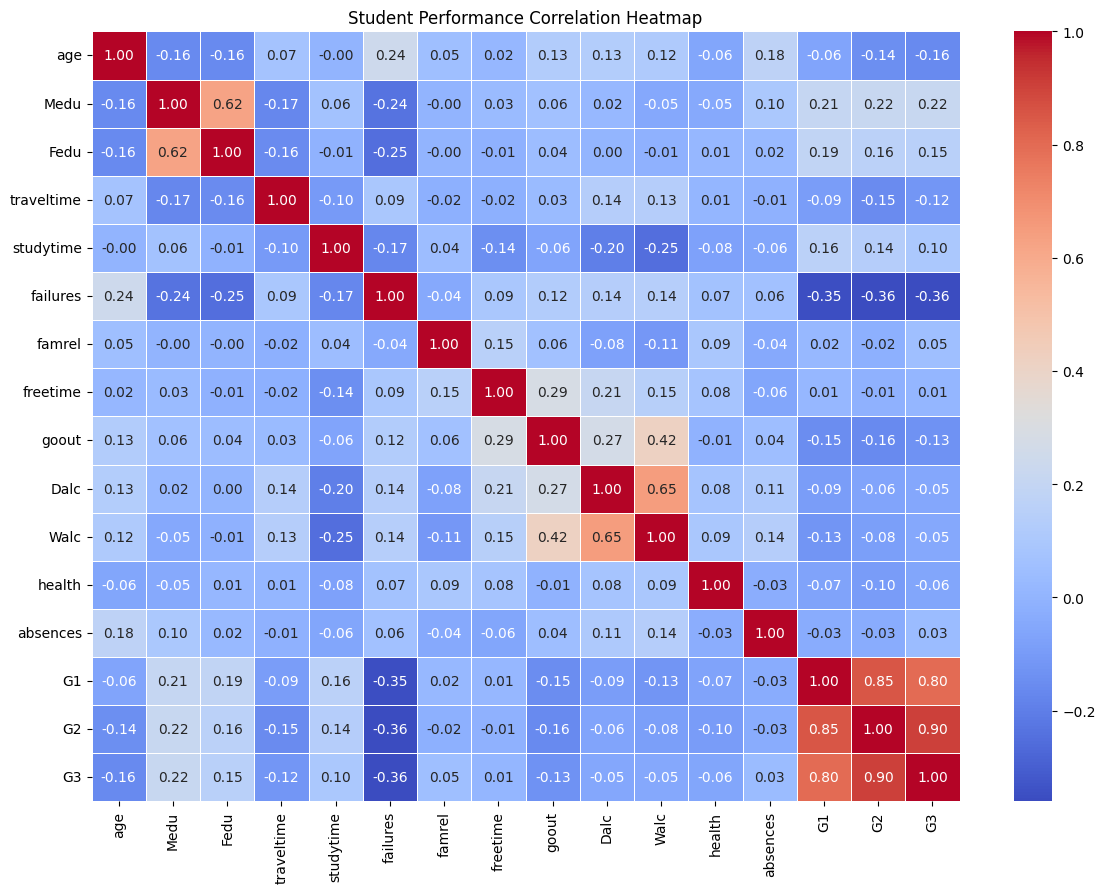

In [15]:

# Set graph size
plt.figure(figsize=(14, 10))

# Create correlation heatmap
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

# Add title
plt.title("Student Performance Correlation Heatmap")

# Display graph
plt.show()


In [16]:

# Get correlations with final grade
grade_correlation = correlation['G3']

# Sort from highest to lowest
grade_correlation = grade_correlation.sort_values(
    ascending=False
)

# Display results
print(grade_correlation)


G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


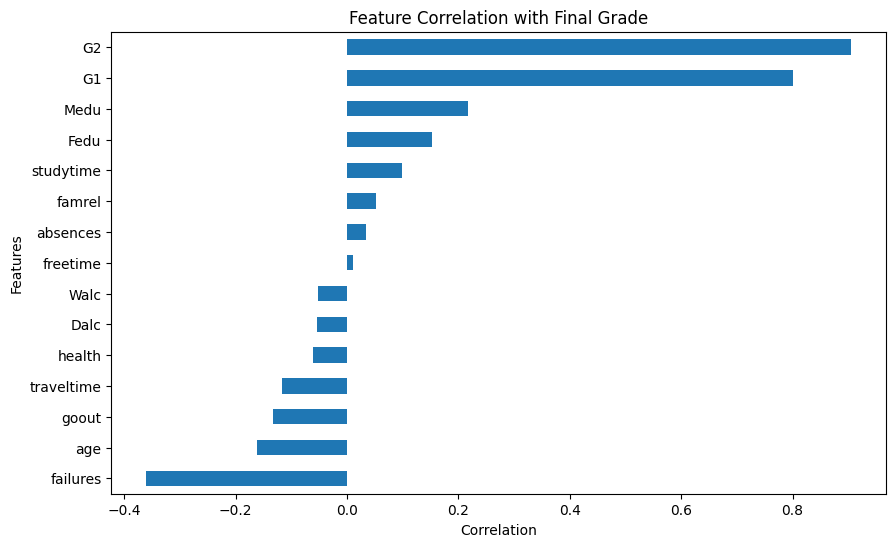

In [17]:

# Remove G3's correlation with itself
grade_features = grade_correlation.drop('G3')

# Create graph
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
grade_features.sort_values().plot(
    kind='barh'
)

plt.title("Feature Correlation with Final Grade")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()


In [18]:

# Create a copy of the original dataset
df_clean = df.copy()

# Display the first five records
df_clean.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [19]:

# Count missing values in each column
missing_values = df_clean.isnull().sum()

# Display columns containing missing values
print(missing_values[missing_values > 0])


Series([], dtype: int64)


In [20]:

# Count duplicate records before cleaning
print("Duplicates before cleaning:", df_clean.duplicated().sum())

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Check duplicates again
print("Duplicates after cleaning:", df_clean.duplicated().sum())


Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [21]:

# Display data types
print(df_clean.dtypes)



school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


In [22]:

# Count students in each category
print(df_clean['sex'].value_counts())


sex
F    208
M    187
Name: count, dtype: int64


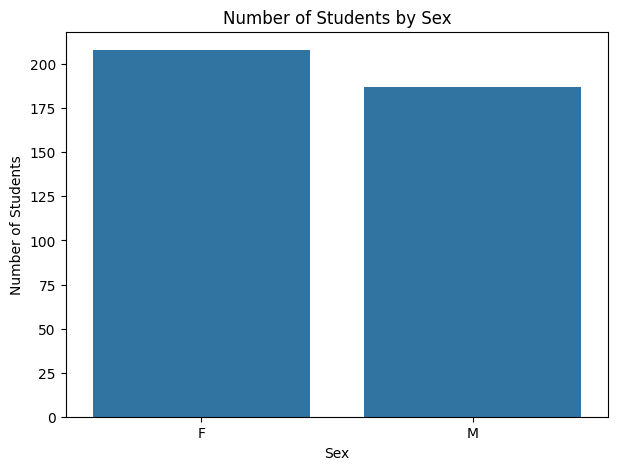

In [23]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='sex')

plt.title("Number of Students by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Students")

plt.show()


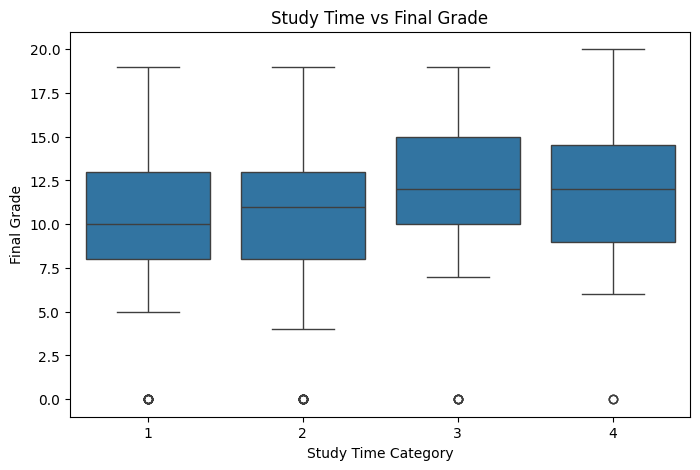

In [24]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x='studytime', y='G3')

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade")

plt.show()


##NEW FEATURE

In [25]:

# Create a new feature
df_clean['average_previous_grade'] = (
    df_clean['G1'] + df_clean['G2']
) / 2

# Display selected columns
df_clean[
    ['G1', 'G2', 'average_previous_grade', 'G3']
].head(10)


,G1,G2,average_previous_grade,G3
0,5,6,5.5,6
1,5,5,5.0,6
2,7,8,7.5,10
3,15,14,14.5,15
4,6,10,8.0,10
5,15,15,15.0,15
6,12,12,12.0,11
7,6,5,5.5,6
8,16,18,17.0,19
9,14,15,14.5,15


In [26]:

print("Original Dataset Shape:", df.shape)

print("Cleaned Dataset Shape:", df_clean.shape)

print("Missing Values:", df_clean.isnull().sum().sum())

print("Duplicate Records:", df_clean.duplicated().sum())

print("New Feature Created:",
      'average_previous_grade' in df_clean.columns)


Original Dataset Shape: (395, 33)
Cleaned Dataset Shape: (395, 34)
Missing Values: 0
Duplicate Records: 0
New Feature Created: True


##DATA INSIGHTS

In [30]:
#nThis gives us a numerical overview of student performance.
# Average final grade
print("Average Final Grade:",
      round(df_clean['G3'].mean(), 2))

# Highest final grade
print("Highest Final Grade:",
      df_clean['G3'].max())

# Lowest final grade
print("Lowest Final Grade:",
      df_clean['G3'].min())

# Average absences
print("Average Absences:",
      round(df_clean['absences'].mean(), 2))

# Average study time
print("Average Study Time:",
      round(df_clean['studytime'].mean(), 2))


Average Final Grade: 10.42
Highest Final Grade: 20
Lowest Final Grade: 0
Average Absences: 5.71
Average Study Time: 2.04


In [28]:
#This helps us inspect the characteristics of students with the highest final grades.
# Sort students by final grade
top_students = df_clean.sort_values(
    by='G3',
    ascending=False
)

# Display top 10 students
top_students[['studytime', 'absences', 'G1', 'G2', 'G3']].head(10)


,studytime,absences,G1,G2,G3
47,4,4,19,19,20
286,3,5,18,18,19
374,3,0,19,18,19
110,1,6,18,19,19
8,2,0,16,18,19
113,1,10,18,19,19
91,1,4,16,17,18
42,2,2,19,18,18
36,3,2,15,16,18
104,2,0,16,18,18


In [29]:
#This gives us evidence to investigate whether study time is associated with academic performance.
# Calculate average final grades by study time
study_results = df_clean.groupby(
    'studytime'
)['G3'].mean().reset_index()

print(study_results)


   studytime         G3
0          1  10.047619
1          2  10.171717
2          3  11.400000
3          4  11.259259


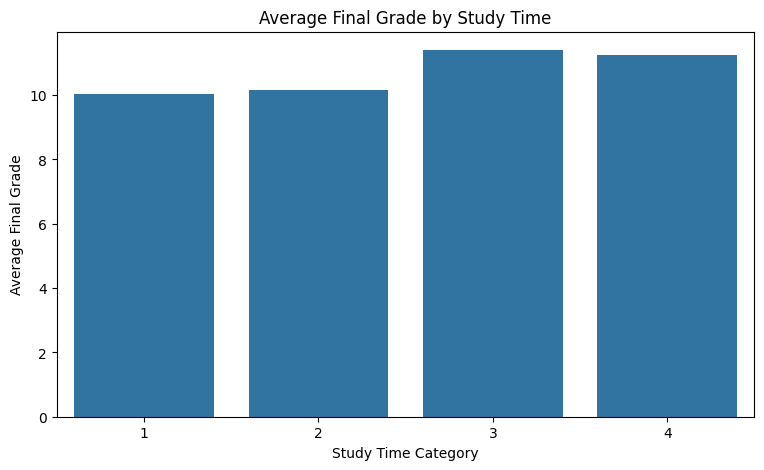

In [31]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=study_results,
    x='studytime',
    y='G3'
)

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")

plt.savefig("study_time_analysis.png",
            dpi=300,
            bbox_inches="tight")

plt.show()


##CONCLUSION

In [32]:

# Calculate correlations with final grade
grade_corr = df_clean.corr(
    numeric_only=True
)['G3'].drop('G3')

# Find strongest positive and negative correlations
print("Strongest positive correlation:")
print(grade_corr.idxmax(), round(grade_corr.max(), 3))

print("\nStrongest negative correlation:")
print(grade_corr.idxmin(), round(grade_corr.min(), 3))

# Study time comparison
print("\nStudy time analysis:")
print(study_results)


Strongest positive correlation:
G2 0.905

Strongest negative correlation:
failures -0.36

Study time analysis:
   studytime         G3
0          1  10.047619
1          2  10.171717
2          3  11.400000
3          4  11.259259


In [34]:

from google.colab import files

files.download('study_time_analysis.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>